# Interactive Few-Shot Ordinal-Aware CLIP for DR Grading

This notebook demonstrates how to load the MMRDR dataset, visualize the data, construct the L2RCLIP + CLIP-DR framework, and run the training loop entirely within the notebook.

In [1]:
import os
import sys
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from omegaconf import OmegaConf
import pytorch_lightning as pl
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import warnings
warnings.filterwarnings('ignore')

# Ensure we are in the Workspace root directory
while not os.path.exists('configs') and os.path.basename(os.getcwd()) != 'MMRDR':
    os.chdir('..')

# Make sure src can be imported
sys.path.append(os.getcwd())

print("Current Working Directory:", os.getcwd())


d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Current Working Directory: d:\Research\Dr.Mohammad(LAB)\ordinal classify\MMRDR\Workspace


## 1. Load Configuration
We will use the CFP config for a 4-shot experiment.

In [2]:
# Load the base config and CFP-specific overrides
base_cfg = OmegaConf.load('configs/default.yaml')
cfp_cfg = OmegaConf.load('configs/mrdr_cfp.yaml')
cfg = OmegaConf.merge(base_cfg, cfp_cfg)

# Set specific few-shot parameters for this interactive run
cfg.data.k_shot = 4
cfg.data.seed = 1 # Must be 1-5 as per the generated splits
cfg.train.epochs = 3 # Keep it short for demonstration

print("Configuration:")
print(OmegaConf.to_yaml(cfg))


Configuration:
runner: src.models.runner.FewShotOrdinalRunner
model:
  image_encoder:
    name: RN50
    lora:
      enabled: true
      r: 16
  text_encoder:
    name: RN50
  prompt_learner:
    name: rankformer_prompt_learner
    num_ranks: 5
    num_tokens_for_context: 16
    attn_heads: 4
  sms:
    enabled: true
data:
  modality: CFP
  k_shot: 4
  seed: 1
  batch_query: 32
  image_size: 224
  manifest: data/MMRDR/CFP_manifest.csv
  splits_dir: data/MMRDR/splits
  num_workers: 4
loss:
  lambda_rank: 1.0
  mu_pairwise: 0.5
  tau: 1.0
train:
  epochs: 3
  optimizer: adam
  lr: 0.0001
  weight_decay: 0.0001
metrics:
- qwk
- mae
- macro_f1
- auc
- acc
- los
defaults:
- default



## 2. Initialize DataModule and Visualize Data
Let's load the PyTorch Lightning DataModule. We assume `prepare_mmrdr.py` and `build_splits.py` have already generated the manifests and splits.

In [3]:
from src.data.datamodule import FewShotDataModule

pl.seed_everything(cfg.data.seed)
datamodule = FewShotDataModule(cfg)
datamodule.setup()

print(f"Support set size (Train): {len(datamodule.support_dataset)}")
print(f"Query set size (Val): {len(datamodule.query_dataset)}")
print(f"Test set size (Test): {len(datamodule.test_dataset)}")


Seed set to 1


Support set size (Train): 20
Query set size (Val): 8873
Test set size (Test): 2225


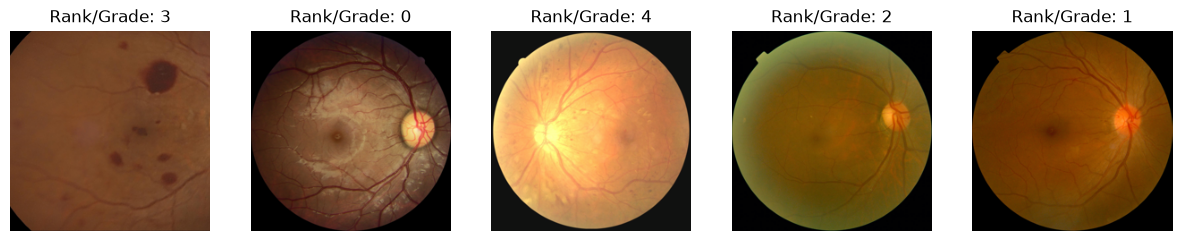

In [4]:
# Visualize a few support images
support_loader = datamodule.train_dataloader()
images, targets, lesions, paths = next(iter(support_loader))

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
for i in range(5):
    # Un-normalize image for visualization
    img = images[i].permute(1, 2, 0).numpy()
    mean = np.array([0.48145466, 0.4578275, 0.40821073])
    std = np.array([0.26862954, 0.26130258, 0.27577711])
    img = std * img + mean
    img = np.clip(img, 0, 1)
    
    axes[i].imshow(img)
    axes[i].set_title(f"Rank/Grade: {targets[i].item()}")
    axes[i].axis('off')
plt.show()


## 3. Initialize the Model
We build the `FewShotOrdinalRunner` which contains CLIP, LoRA, the RankFormer Prompt Learner, and the SMS calibration module.

In [5]:
from src.models.runner import FewShotOrdinalRunner

model = FewShotOrdinalRunner(cfg)


Trainable parameters: 27546545


## 4. Training Loop
We use PyTorch Lightning's Trainer to handle the loop. We will enable the progress bar to see the training happen step-by-step.

In [ ]:
# Initialize the Trainer
trainer = pl.Trainer(
    max_epochs=cfg.train.epochs,
    accelerator="auto",
    devices=1,
    precision="16-mixed",
    log_every_n_steps=1,
    enable_checkpointing=False # Disable saving weights for this demo
)

# Start training!
trainer.fit(model, datamodule=datamodule)


Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name               ┃ Type                    ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ clip_model         │ CLIP                    │  103 M │ eval  │     0 │
│ 1 │ text_encoder       │ TextEncoder             │ 38.4 M │ train │     0 │
│ 2 │ prompt_learner     │ RankFormerPromptLearner │  1.1 M │ train │     0 │
│ 3 │ sms                │ SMS                     │      0 │ train │     0 │
│ 4 │ criterion_main     │ CrossEntropyLoss        │      0 │ train │     0 │
│ 5 │ criterion_rank     │ RankingAwareLoss        │      0 │ train │     0 │
│ 6 │ criterion_pairwise │ CrossModalPairwiseLoss  │      0 │ train │     0 │
└───┴────────────────────┴─────────────────────────┴────────┴───────┴───────┘

Trainable params: 27.5 M                                                                                           
Non-trainable params: 76.7 M                                                                                       
Total params: 104 M                                                                                                
Total estimated model params size (MB): 417.027                                                                    
Modules in train mode: 520                                                                                         
Modules in eval mode: 325                                                                                          
Total FLOPs: 0

## 5. Evaluation and Analysis
Finally, we evaluate on the unseen test set and plot a confusion matrix.

In [ ]:
# Run testing
trainer.test(model, datamodule=datamodule)

# Fetch latest metrics logged by the model
print("\nFinal Metrics on Test Set:")
for k, v in model.latest_metrics.items():
    print(f"{k.upper()}: {v:.4f}")


In [ ]:
# Plot Confusion Matrix
# We can access the stored predictions and targets from the validation/test step
# (We'll re-run a quick inference loop over a subset of test data for the plot)
model.eval()
model.to('cuda' if torch.cuda.is_available() else 'cpu')

all_preds = []
all_targets = []

with torch.no_grad():
    for images, targets, _, _ in datamodule.test_dataloader():
        images = images.to(model.device)
        image_features, text_features = model(images)
        
        logit_scale = model.clip_model.logit_scale.exp()
        sim = logit_scale * image_features @ text_features.T
        
        if model.sms is not None:
            sim = model.sms(sim)
            
        preds = sim.argmax(dim=-1).cpu().numpy()
        all_preds.extend(preds)
        all_targets.extend(targets.numpy())
        
        if len(all_preds) > 500: # Stop early for fast plotting
            break

cm = confusion_matrix(all_targets, all_preds, labels=range(cfg.model.prompt_learner.num_ranks))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(cfg.model.prompt_learner.num_ranks))
fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap='Blues', colorbar=False)
plt.title("Test Set Confusion Matrix")
plt.show()
